Split Sizes -> Train(17-21): 36838 | Val(22): 8760 (Real: 8153) | Test(23): 8712 (Real: 7630)

=== STEP A: 2022 VALIDATION TUNING & PROBABILITY CALIBRATION ===
2022 Residual Quantiles -> q10: -96.28, q90: 137.42, MAE: 73.33
Locked on 2022 Val -> weight_mult=1.0, raw_threshold=0.45 (2022 Val F1=0.636)

=== STEP B: 5-SEED RUNS & 2023 TEST EVALUATION ===
2023 Test Brier Score -> Uncalibrated: 0.1363 | 2022-Isotonic Calibrated: 0.1126
2023 Empirical Coverage of 2022-Calibrated Band: 83.1%


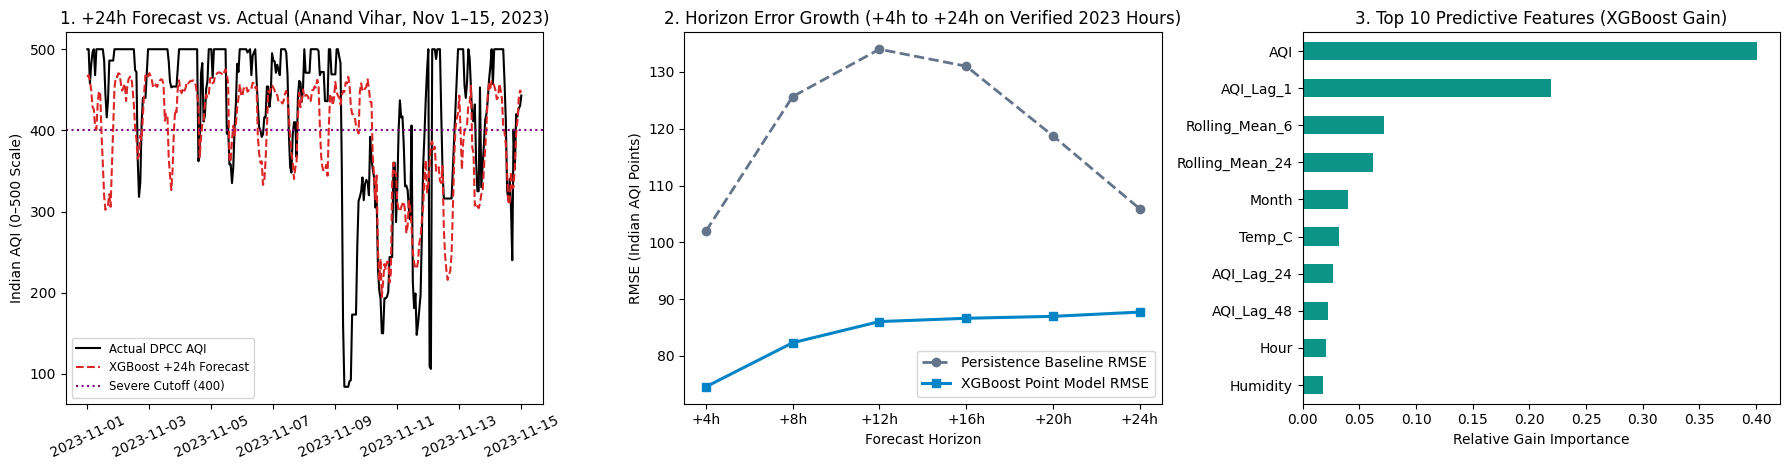

Regenerated evaluation figure at: ../Models\model_evaluation_plots.png
Updated ../Models\model_metadata.json with fresh timestamp: 2026-10-25 18:14:21 UTC


In [4]:
# ==============================================================================
# NOTEBOOK: 02_model_training_and_validation.ipynb
# Complete Reproducible Pipeline:
#   1. 3-Way Split (2017-2021 Train | 2022 Val | 2023 Test)
#   2. 2022 Interval Calibration + 2022 Severe-Day Hyperparameter & Isotonic Calibration
#   3. 5-Seed Stability Evaluation on 2023 Test Set
#   4. Multi-Horizon Models (+4h to +24h) vs. Horizon Persistence
#   5. Regenerate High-Res Evaluation Plot & Export Native JSON Models + Metadata
# ==============================================================================
import os
import json
import hashlib
import warnings
from datetime import datetime, timezone

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.isotonic import IsotonicRegression
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss
)

DATA_PATH = "../Dataset/ml_ready_data.csv"
MODELS_DIR = "../Models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Remove any stale .pkl bundle so only clean JSON models & metadata remain
stale_pkl = os.path.join(MODELS_DIR, "aqi_xgboost_bundle.pkl")
if os.path.exists(stale_pkl):
    os.remove(stale_pkl)
    print(f"Removed stale pickle file: {stale_pkl}")

with open(DATA_PATH, "rb") as f:
    dataset_sha256 = hashlib.sha256(f.read()).hexdigest()

df_ml = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])

feature_cols = [
    "AQI", "AQI_Lag_1", "AQI_Lag_3", "AQI_Lag_6", "AQI_Lag_24", "AQI_Lag_48",
    "Rolling_Mean_6", "Rolling_Mean_24", "Rolling_Std_24", "AQI_Diff_24",
    "Temp_C", "Humidity", "Wind_Speed",
    "Hour", "Month", "DayOfWeek", "Is_Weekend"
]

horizons = [4, 8, 12, 16, 20, 24]
for h in horizons:
    df_ml[f"Target_{h}h"] = df_ml["AQI"].shift(-h)
    df_ml[f"Real_{h}h"] = df_ml["is_real"].shift(-h)

df_ml = df_ml.dropna().reset_index(drop=True)

# 1. Strict 3-Way Chronological Split
mask_train_sub = df_ml["Datetime"].dt.year <= 2021
mask_val_2022 = df_ml["Datetime"].dt.year == 2022
mask_train_full = df_ml["Datetime"].dt.year <= 2022
mask_test_2023 = df_ml["Datetime"].dt.year == 2023

X_tr_sub = df_ml.loc[mask_train_sub, feature_cols]
y_tr_sub = df_ml.loc[mask_train_sub, "Target_24h"]

X_val = df_ml.loc[mask_val_2022, feature_cols]
y_val = df_ml.loc[mask_val_2022, "Target_24h"]
real_val = df_ml.loc[mask_val_2022, "Real_24h"].astype(bool)

X_tr_full = df_ml.loc[mask_train_full, feature_cols]
y_tr_full = df_ml.loc[mask_train_full, "Target_24h"]

X_test = df_ml.loc[mask_test_2023, feature_cols]
y_test = df_ml.loc[mask_test_2023, "Target_24h"]
real_test = df_ml.loc[mask_test_2023, "Real_24h"].astype(bool)

print(f"Split Sizes -> Train(17-21): {len(X_tr_sub)} | Val(22): {len(X_val)} (Real: {real_val.sum()}) | Test(23): {len(X_test)} (Real: {real_test.sum()})")

# ==============================================================================
# STEP A: 2022 VALIDATION TUNING, INTERVAL CALIBRATION & ISOTONIC CALIBRATION
# ==============================================================================
print("\n=== STEP A: 2022 VALIDATION TUNING & PROBABILITY CALIBRATION ===")
xgb_val_reg = XGBRegressor(
    n_estimators=250, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
)
xgb_val_reg.fit(X_tr_sub, y_tr_sub)
val_preds_24 = np.clip(xgb_val_reg.predict(X_val), 40.0, 500.0)

val_residuals_real = y_val[real_val] - val_preds_24[real_val]
q10_val = float(np.percentile(val_residuals_real, 10))
q90_val = float(np.percentile(val_residuals_real, 90))
mae_val = float(mean_absolute_error(y_val[real_val], val_preds_24[real_val]))
print(f"2022 Residual Quantiles -> q10: {q10_val:.2f}, q90: {q90_val:.2f}, MAE: {mae_val:.2f}")

y_tr_sub_sev = (y_tr_sub > 400).astype(int)
y_val_sev = (y_val[real_val] > 400).astype(int)
base_neg_pos = (y_tr_sub_sev == 0).sum() / max(1, (y_tr_sub_sev == 1).sum())

best_val_f1 = -1.0
best_w_mult = 0.65
best_thresh = 0.50
best_val_clf = None

for w_mult in [0.45, 0.55, 0.65, 0.75, 0.85, 1.0]:
    clf_cand = XGBClassifier(
        n_estimators=200, learning_rate=0.04, max_depth=5,
        scale_pos_weight=base_neg_pos * w_mult, random_state=42, n_jobs=-1, eval_metric="logloss"
    )
    clf_cand.fit(X_tr_sub, y_tr_sub_sev)
    val_probs = clf_cand.predict_proba(X_val[real_val])[:, 1]
    for th in [0.40, 0.45, 0.50, 0.55]:
        f1_v = f1_score(y_val_sev, (val_probs >= th).astype(int))
        if f1_v > best_val_f1:
            best_val_f1 = f1_v
            best_w_mult = w_mult
            best_thresh = th
            best_val_clf = clf_cand

# Fit Isotonic Regression Calibrator strictly on 2022 Validation Set raw scores
val_raw_scores = best_val_clf.predict_proba(X_val[real_val])[:, 1]
iso_calibrator = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
iso_calibrator.fit(val_raw_scores, y_val_sev)
print(f"Locked on 2022 Val -> weight_mult={best_w_mult}, raw_threshold={best_thresh:.2f} (2022 Val F1={best_val_f1:.3f})")

# ==============================================================================
# STEP B: 5-SEED STABILITY RUNS & 2023 TEST SET EVALUATION
# ==============================================================================
print("\n=== STEP B: 5-SEED RUNS & 2023 TEST EVALUATION ===")
SEEDS = [42, 100, 2023, 777, 999]
rf_rmses, xgb_rmses, clf_f1s, clf_precs, clf_recs = [], [], [], [], []
best_xgb_reg, best_sev_clf, p_xgb_test_final, p_rf_test_final = None, None, None, None

y_tr_full_sev = (y_tr_full > 400).astype(int)
full_neg_pos = (y_tr_full_sev == 0).sum() / max(1, (y_tr_full_sev == 1).sum())
y_test_sev = (y_test[real_test] > 400).astype(int)

for s in SEEDS:
    rf_s = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10, random_state=s, n_jobs=-1)
    rf_s.fit(X_tr_full, y_tr_full)
    p_rf_s = np.clip(rf_s.predict(X_test), 40.0, 500.0)
    rf_rmses.append(np.sqrt(mean_squared_error(y_test[real_test], p_rf_s[real_test])))

    xgb_s = XGBRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, random_state=s, n_jobs=-1
    )
    xgb_s.fit(X_tr_full, y_tr_full)
    p_xgb_s = np.clip(xgb_s.predict(X_test), 40.0, 500.0)
    xgb_rmses.append(np.sqrt(mean_squared_error(y_test[real_test], p_xgb_s[real_test])))

    clf_s = XGBClassifier(
        n_estimators=200, learning_rate=0.04, max_depth=5,
        scale_pos_weight=full_neg_pos * best_w_mult, random_state=s, n_jobs=-1, eval_metric="logloss"
    )
    clf_s.fit(X_tr_full, y_tr_full_sev)
    prob_s = clf_s.predict_proba(X_test[real_test])[:, 1]
    pred_sev_s = (prob_s >= best_thresh).astype(int)

    clf_f1s.append(f1_score(y_test_sev, pred_sev_s))
    clf_precs.append(precision_score(y_test_sev, pred_sev_s, zero_division=0))
    clf_recs.append(recall_score(y_test_sev, pred_sev_s, zero_division=0))

    if s == 42:
        best_xgb_reg = xgb_s
        best_sev_clf = clf_s
        p_xgb_test_final = p_xgb_s
        p_rf_test_final = p_rf_s

# Evaluate 2022 Isotonic Calibrator on 2023 Test Set
test_raw_scores = best_sev_clf.predict_proba(X_test[real_test])[:, 1]
test_cal_probs = iso_calibrator.transform(test_raw_scores)
brier_raw = float(brier_score_loss(y_test_sev, test_raw_scores))
brier_cal = float(brier_score_loss(y_test_sev, test_cal_probs))
print(f"2023 Test Brier Score -> Uncalibrated: {brier_raw:.4f} | 2022-Isotonic Calibrated: {brier_cal:.4f}")

# Empirical Coverage of 2022-Calibrated [q10_val, q90_val] Band on Unseen 2023 Real Hours
y_test_real = y_test[real_test]
p_test_real = p_xgb_test_final[real_test]
in_band_2023 = (
    (y_test_real >= np.clip(p_test_real + q10_val, 40.0, 500.0)) &
    (y_test_real <= np.clip(p_test_real + q90_val, 40.0, 500.0))
)
coverage_2023_pct = float(in_band_2023.mean() * 100.0)
print(f"2023 Empirical Coverage of 2022-Calibrated Band: {coverage_2023_pct:.1f}%")

# ==============================================================================
# STEP C: REGRESSION, SEVERE CLASSIFICATION & MULTI-HORIZON AUDIT TABLES
# ==============================================================================
y_naive_test = X_test["AQI"].values
lr_full = LinearRegression().fit(X_tr_full, y_tr_full)
p_lr_test = np.clip(lr_full.predict(X_test), 40.0, 500.0)

regression_metrics = [
    {
        "Model": "Naive Baseline (24h Persistence)",
        "RMSE (All 2023)": round(float(np.sqrt(mean_squared_error(y_test, y_naive_test))), 2),
        "RMSE (Real Only)": round(float(np.sqrt(mean_squared_error(y_test_real, y_naive_test[real_test]))), 2),
        "MAE (Real Only)": round(float(mean_absolute_error(y_test_real, y_naive_test[real_test])), 2),
        "R2 (Real Only)": round(float(r2_score(y_test_real, y_naive_test[real_test])), 3),
        "5-Seed Spread (SD)": "0.00 (Deterministic)"
    },
    {
        "Model": "Linear Regression",
        "RMSE (All 2023)": round(float(np.sqrt(mean_squared_error(y_test, p_lr_test))), 2),
        "RMSE (Real Only)": round(float(np.sqrt(mean_squared_error(y_test_real, p_lr_test[real_test]))), 2),
        "MAE (Real Only)": round(float(mean_absolute_error(y_test_real, p_lr_test[real_test])), 2),
        "R2 (Real Only)": round(float(r2_score(y_test_real, p_lr_test[real_test])), 3),
        "5-Seed Spread (SD)": "0.00 (Deterministic)"
    },
    {
        "Model": "Random Forest Regressor",
        "RMSE (All 2023)": round(float(np.sqrt(mean_squared_error(y_test, p_rf_test_final))), 2),
        "RMSE (Real Only)": round(float(np.mean(rf_rmses)), 2),
        "MAE (Real Only)": round(float(mean_absolute_error(y_test_real, p_rf_test_final[real_test])), 2),
        "R2 (Real Only)": round(float(r2_score(y_test_real, p_rf_test_final[real_test])), 3),
        "5-Seed Spread (SD)": f"±{np.std(rf_rmses):.2f}"
    },
    {
        "Model": "XGBoost Regressor (+24h)",
        "RMSE (All 2023)": round(float(np.sqrt(mean_squared_error(y_test, p_xgb_test_final))), 2),
        "RMSE (Real Only)": round(float(np.mean(xgb_rmses)), 2),
        "MAE (Real Only)": round(float(mean_absolute_error(y_test_real, p_xgb_test_final[real_test])), 2),
        "R2 (Real Only)": round(float(r2_score(y_test_real, p_xgb_test_final[real_test])), 3),
        "5-Seed Spread (SD)": f"±{np.std(xgb_rmses):.2f}"
    }
]

def get_sev_row(name, y_true_bin, y_pred_bin, split_label):
    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
    return {
        "Method": name,
        "Eval Split": split_label,
        "Precision": round(float(precision_score(y_true_bin, y_pred_bin, zero_division=0)), 3),
        "Recall (Sensitivity)": round(float(recall_score(y_true_bin, y_pred_bin, zero_division=0)), 3),
        "F1-Score": round(float(f1_score(y_true_bin, y_pred_bin, zero_division=0)), 3),
        "Missed Severe Hours (FN)": int(fn),
        "False Alarms (FP)": int(fp)
    }

val_sev_preds = (val_raw_scores >= best_thresh).astype(int)
test_sev_preds = (test_raw_scores >= best_thresh).astype(int)

severe_classification_metrics = [
    get_sev_row("Naive Persistence (AQI > 400)", y_val_sev, (X_val.loc[real_val, "AQI"] > 400).astype(int), "2022 Val"),
    get_sev_row("Thresholded XGBRegressor (> 400)", y_val_sev, (val_preds_24[real_val] > 400).astype(int), "2022 Val"),
    get_sev_row("Dedicated XGBClassifier (Tuned)", y_val_sev, val_sev_preds, "2022 Val"),
    get_sev_row("Naive Persistence (AQI > 400)", y_test_sev, (y_naive_test[real_test] > 400).astype(int), "2023 Test"),
    get_sev_row("Thresholded XGBRegressor (> 400)", y_test_sev, (p_test_real > 400).astype(int), "2023 Test"),
    get_sev_row(f"Dedicated XGBClassifier (5-Seed F1: {np.mean(clf_f1s):.3f}±{np.std(clf_f1s):.3f})", y_test_sev, test_sev_preds, "2023 Test")
]

horizon_metrics = []
for h in horizons:
    y_tr_h = df_ml.loc[mask_train_full, f"Target_{h}h"]
    y_te_h = df_ml.loc[mask_test_2023, f"Target_{h}h"]
    real_te_h = df_ml.loc[mask_test_2023, f"Real_{h}h"].astype(bool)

    if h == 24:
        m_h = best_xgb_reg
    else:
        m_h = XGBRegressor(
            n_estimators=200, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
        )
        m_h.fit(X_tr_full, y_tr_h)

    m_h.get_booster().save_model(os.path.join(MODELS_DIR, f"xgb_horizon_{h}h.json"))
    pred_h = np.clip(m_h.predict(X_test), 40.0, 500.0)
    rmse_mod = float(np.sqrt(mean_squared_error(y_te_h[real_te_h], pred_h[real_te_h])))
    mae_mod = float(mean_absolute_error(y_te_h[real_te_h], pred_h[real_te_h]))
    rmse_pers = float(np.sqrt(mean_squared_error(y_te_h[real_te_h], y_naive_test[real_te_h])))
    skill_pct = ((rmse_pers - rmse_mod) / rmse_pers) * 100.0

    horizon_metrics.append({
        "Horizon": f"+{h}h Ahead",
        "XGBoost RMSE (Real)": round(rmse_mod, 2),
        "Persistence RMSE (Real)": round(rmse_pers, 2),
        "XGBoost MAE (Real)": round(mae_mod, 2),
        "Skill vs Persistence": f"+{skill_pct:.1f}%"
    })

best_sev_clf.get_booster().save_model(os.path.join(MODELS_DIR, "xgb_severe_clf.json"))

# ==============================================================================
# STEP D: REGENERATE UPDATED MODEL EVALUATION PLOT FOR REPORT & UI
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Panel 1: Nov 2023 Smog Episode Forecast vs Actual
dates_2023 = df_ml.loc[mask_test_2023, "Datetime"]
nov_mask = (dates_2023 >= "2023-11-01") & (dates_2023 <= "2023-11-15")
axes[0].plot(dates_2023[nov_mask], y_test[nov_mask], label="Actual DPCC AQI", color="black", linewidth=1.5)
axes[0].plot(dates_2023[nov_mask], p_xgb_test_final[nov_mask], label="XGBoost +24h Forecast", color="#dc2626", linestyle="--", linewidth=1.5)
axes[0].axhline(400, color="purple", linestyle=":", label="Severe Cutoff (400)")
axes[0].set_title("1. +24h Forecast vs. Actual (Anand Vihar, Nov 1–15, 2023)")
axes[0].set_ylabel("Indian AQI (0–500 Scale)")
axes[0].legend(loc="lower left", fontsize=8.5)
axes[0].tick_params(axis="x", rotation=25)

# Panel 2: Multi-Horizon RMSE Curve (+4h to +24h vs Persistence)
h_labels = [r["Horizon"].replace(" Ahead", "") for r in horizon_metrics]
h_xgb_rmse = [r["XGBoost RMSE (Real)"] for r in horizon_metrics]
h_pers_rmse = [r["Persistence RMSE (Real)"] for r in horizon_metrics]
axes[1].plot(h_labels, h_pers_rmse, marker="o", color="#64748b", linestyle="--", linewidth=2, label="Persistence Baseline RMSE")
axes[1].plot(h_labels, h_xgb_rmse, marker="s", color="#0284c7", linewidth=2.2, label="XGBoost Point Model RMSE")
axes[1].set_title("2. Horizon Error Growth (+4h to +24h on Verified 2023 Hours)")
axes[1].set_xlabel("Forecast Horizon")
axes[1].set_ylabel("RMSE (Indian AQI Points)")
axes[1].legend()

# Panel 3: Top 10 Feature Importances
imp = pd.Series(best_xgb_reg.feature_importances_, index=feature_cols).sort_values().tail(10)
imp.plot(kind="barh", color="#0d9488", ax=axes[2])
axes[2].set_title("3. Top 10 Predictive Features (XGBoost Gain)")
axes[2].set_xlabel("Relative Gain Importance")

plt.tight_layout()
plot_out_path = os.path.join(MODELS_DIR, "model_evaluation_plots.png")
plt.savefig(plot_out_path, dpi=300)
plt.show()
print(f"Regenerated evaluation figure at: {plot_out_path}")

# ==============================================================================
# STEP E: EXPORT COMPLETE METADATA JSON (WITH FRESH UTC TIMESTAMP & CALIBRATION)
# ==============================================================================
metadata = {
    "trained_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC"),
    "dataset_file": "ml_ready_data.csv",
    "dataset_sha256": dataset_sha256,
    "row_counts": {
        "total": int(len(df_ml)),
        "train_2017_2021": int(len(X_tr_sub)),
        "val_2022_total": int(len(X_val)),
        "val_2022_real": int(real_val.sum()),
        "test_2023_total": int(len(X_test)),
        "test_2023_real": int(real_test.sum())
    },
    "library_versions": {
        "xgboost": xgb.__version__,
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    },
    "feature_cols": feature_cols,
    "horizons": horizons,
    "val_2022_calibration": {
        "q10_err": round(q10_val, 2),
        "q90_err": round(q90_val, 2),
        "mae_val": round(mae_val, 2),
        "severe_weight_mult": best_w_mult,
        "severe_prob_threshold": best_thresh,
        "test_2023_empirical_coverage_pct": round(coverage_2023_pct, 1),
        "isotonic_x_thresholds": [round(float(x), 5) for x in iso_calibrator.X_thresholds_],
        "isotonic_y_thresholds": [round(float(y), 5) for y in iso_calibrator.y_thresholds_],
        "brier_score_2023_uncalibrated": round(brier_raw, 4),
        "brier_score_2023_calibrated": round(brier_cal, 4)
    },
    "regression_metrics": regression_metrics,
    "severe_classification_metrics": severe_classification_metrics,
    "horizon_metrics": horizon_metrics
}

meta_out_path = os.path.join(MODELS_DIR, "model_metadata.json")
with open(meta_out_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Updated {meta_out_path} with fresh timestamp: {metadata['trained_at_utc']}")